# 07: Baseline Forecasting Benchmarks
**Milestone 2: Week 4 — Step 14**

This notebook establishes empirical baseline performance hurdles scored on the validation period (1 June to 31 July 2026):
1. **Same hour last week:** Ridership 7 days earlier (`lag_7d`)
2. **4-week average:** Average of 7, 14, 21, and 28-day lags (`lag_mean_available`)

Three error metrics are reported:
- **MAE:** Mean Absolute Error (in riders)
- **RMSE:** Root Mean Squared Error (penalizes large misses)
- **WAPE:** Weighted Absolute Percentage Error ($\sum |y - \hat{y}| \div \sum y$)

> **Milestone 3 Hurdle:** Every predictive machine learning model developed in Milestone 3 must beat these baseline scores.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from src.eda_utils import typical_days, DAY_TYPE_COLORS, calc_period_ratio, calc_cv

DATA = ROOT / "data" / "processed"
FIG = ROOT / "reports" / "figures"
TAB = ROOT / "reports" / "tables"
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)

matched = pd.read_parquet(DATA / "matched_hourly.parquet")
profiles = pd.read_parquet(DATA / "route_profiles.parquet")
print(f"Loaded matched hourly: {len(matched):,} rows (41 routes)")
print(f"Loaded route profiles: {len(profiles)} routes")


Loaded matched hourly: 233,227 rows (41 routes)
Loaded route profiles: 41 routes


## Step 14.1: Overall Network Baseline Performance
Evaluated across all 54,046 validation rows (June–July 2026).

In [2]:
overall = pd.read_csv(TAB / 'm2_baseline_forecast_overall.csv')
print('Overall Validation Baseline Metrics:')
overall

Overall Validation Baseline Metrics:


,model_name,evaluated_rows,coverage_pct,mae,rmse,wape_pct
0,Same hour last week (lag_7d),53632,99.23,44.23,81.42,17.48
1,4-week average (lag_mean_available),53745,99.44,35.56,63.15,14.08


## Step 14.2: Per-Route Benchmark Performance
Examines error metrics across individual routes. High-volume trunk lines achieve WAPE $\approx 11-13\%$, while low-volume feeder shuttles register higher percentage errors despite lower absolute errors.

In [3]:
per_route = pd.read_csv(TAB / 'm2_baseline_forecast_per_route.csv')
print(f'Total routes evaluated: {len(per_route)}')
print('\nTop 15 Routes by Volume with Baseline Errors:')
per_route.sort_values('total_riders', ascending=False).head(15)

Total routes evaluated: 41

Top 15 Routes by Volume with Baseline Errors:


,route,total_riders,lag7_mae,lag7_rmse,lag7_wape_pct,avg4wk_mae,avg4wk_rmse,avg4wk_wape_pct,best_baseline
14,M15+,1264666,148.13,266.54,14.61,119.56,196.48,11.93,4-week average
13,M15,754794,81.47,117.91,15.80,67.29,97.54,13.05,4-week average
37,M86+,699355,62.35,114.15,13.05,54.32,91.87,11.37,4-week average
2,M101,643638,73.76,109.91,16.78,59.16,88.83,13.46,4-week average
12,M14D+,618398,53.99,92.77,12.78,46.61,75.08,11.03,4-week average
25,M4,581505,66.37,104.64,14.17,53.13,80.65,11.44,4-week average
39,M96,477198,50.92,90.78,15.62,41.39,70.82,12.70,4-week average
20,M3,469131,53.01,80.66,14.56,43.15,63.81,11.89,4-week average
31,M60+,460171,42.16,60.71,13.41,32.82,46.55,10.44,4-week average
7,M11,443712,47.39,73.74,14.05,39.21,58.04,11.64,4-week average


## Step 14.3: Comparison of Baseline Models (WAPE %)
Visualizes how smoothing across 4 historical weeks reduces error compared to a single-lag forecast.

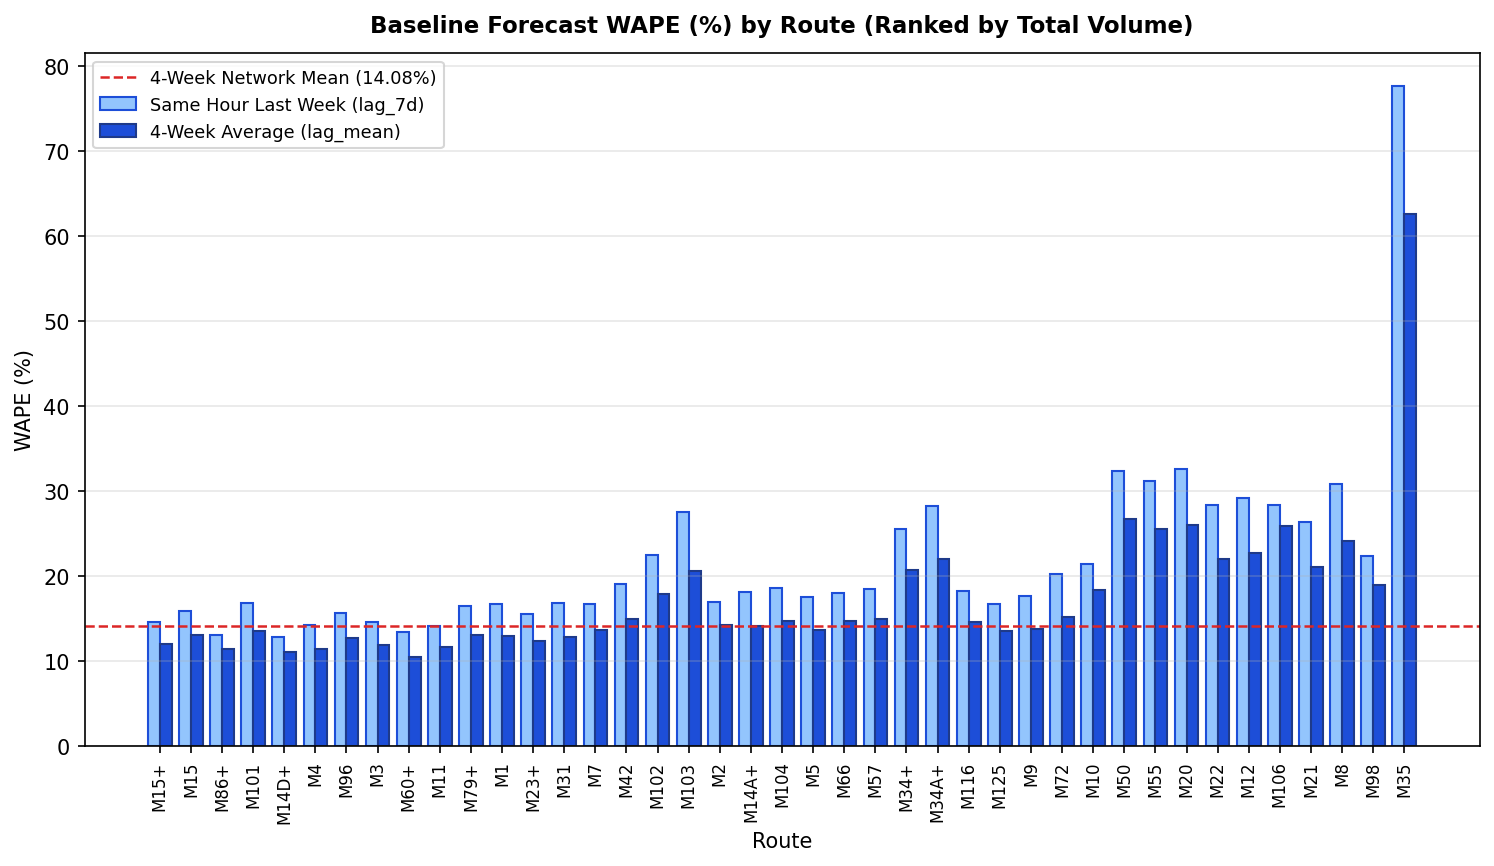

In [4]:
fig, ax = plt.subplots(figsize=(12, 6), dpi=150)
sorted_r = per_route.sort_values('total_riders', ascending=False)
x = np.arange(len(sorted_r))
width = 0.38

ax.bar(x - width/2, sorted_r['lag7_wape_pct'], width, label='Same Hour Last Week (lag_7d)', color='#93c5fd', edgecolor='#1d4ed8')
ax.bar(x + width/2, sorted_r['avg4wk_wape_pct'], width, label='4-Week Average (lag_mean)', color='#1d4ed8', edgecolor='#1e3a8a')

ax.set_title('Baseline Forecast WAPE (%) by Route (Ranked by Total Volume)', fontsize=11, fontweight='bold', pad=10)
ax.set_ylabel('WAPE (%)', fontsize=10)
ax.set_xlabel('Route', fontsize=10)
ax.set_xticks(x)
ax.set_xticklabels(sorted_r['route'], rotation=90, fontsize=8)
ax.axhline(overall.loc[1, 'wape_pct'], color='#dc2626', linestyle='--', linewidth=1.2, label=f'4-Week Network Mean ({overall.loc[1, "wape_pct"]}%)')
ax.grid(axis='y', alpha=0.3)
ax.legend(fontsize=8.5)
fig.savefig(FIG / 'm2_baseline_wape_comparison.png', dpi=150, bbox_inches='tight')
plt.show()